# Анализ и прогнозирование временных рядов методами искусственного интеллекта
# Артемьев М.О. ЕТ-228
## **Практическая работа 4. Матричный профиль. Поиск примитивов на его основе.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы четвертой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

practice_dir_path = '/content/drive/MyDrive/04 Matrix profile'

os.chdir(practice_dir_path)

if practice_dir_path not in sys.path:
    sys.path.insert(0, practice_dir_path)

print("Рабочая папка:", os.getcwd())
print("Файлы:", os.listdir())

Mounted at /content/drive
Рабочая папка: /content/drive/MyDrive/04 Matrix profile
Файлы: ['04 Matrix profile.zip', 'datasets', 'modules', '04 Matrix profile.ipynb']


Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [45]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Импортируйте библиотеки и модули, необходимые для реализации практической работы 4.

In [3]:
!pip install stumpy

In [4]:
import pandas as pd
import numpy as np
import os
import datetime

from modules.plots import *
from modules.mp import compute_mp
from modules.motifs import top_k_motifs
from modules.discords import top_k_discords
from modules.meter_swapping_detection import *

## **Часть 1.** Матричный профиль. Поиск мотивов и диссонансов.

### **Задача 1.**
Загрузите временной ряд, который содержит данные о почасовом потреблении электроэнергии некоторого итальянского города, снимаемые в течение 3 лет, начиная с 1 января 1995 года.

In [5]:
ts_url = './datasets/part1/italianpowerdemand.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд, используя функцию `plot_ts()` из модуля *plot.py*.

In [6]:
plot_ts(ts, "Input time series")

Анализ временных рядов на основе матричного профиля осуществляет библиотека [stumpy](https://stumpy.readthedocs.io/en/latest/index.html). Напишите функцию `compute_mp()` в модуле *mp.py*, которая вычисляет матричный профиль временного ряда на основе выбранной вами функции из библиотеки *stumpy*.

In [7]:
m = 165
excl_zone = int(np.ceil(m / 2))
mp = {}

mp = compute_mp(ts, m, exclusion_zone=excl_zone)

print("Длина матричного профиля:", len(mp['mp']))
print("Минимальное расстояние:", np.min(mp['mp']))

Длина матричного профиля: 29767
Минимальное расстояние: 1.2266251888855342


Визуализируйте найденный матричный профиль ряда.

In [8]:
plot_ts(mp['mp'], "Matrix Profile")

### **Задача 2.**
Выполните поиск top-$k$ мотивов в исходном временном ряде на основе построенного матричного профиля. Для этого реализуйте самостоятельно функцию `top_k_motifs()` в модуле *motifs.py*. Среди найденных мотивов не должно быть тривиальных совпадений, поэтому в `top_k_motifs()` добавьте вызов функции `apply_exclusion_zone()` из модуля *utils.py*.

In [9]:
top_k = 6
motifs = {}

motifs = top_k_motifs(mp, top_k)

print(motifs)

{'indices': [(17852, 18188), (18539, 27276), (19168, 28073), (18208, 26945), (19343, 28080), (18611, 18779)], 'distances': [1.2266251888855342, 1.2356334381463014, 1.2455578192690095, 1.2457965045564825, 1.2715944340232408, 1.3080603082117044]}


Выполните визуализацию найденных top-$k$ мотивов с помощью функции `plot_motifs()` из *plots.py*.

In [10]:
plot_motifs(mp, motifs)

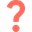
Проанализируйте и изложите содержательный смысл полученных результатов.

## В результате поиска на основе матричного профиля найдены шесть пар наиболее похожих подпоследовательностей временного ряда. Найденные мотивы имеют близкую форму колебаний с повторяющимися подъемами и спадами. Их расположение соответствует областям низких значений матричного профиля, что указывает на наличие повторяющихся закономерностей в данных. Использование зоны исключения позволяет избежать выбора тривиальных совпадений при поиске мотивов.

### **Задача 3.**
Реализуйте самостоятельно функцию `top_k_discords()` в модуле *discords.py*, предназначенную для поиска top-$k$ диссонансов во временном ряде на основе матричного профиля. Чтобы исключить попадание тривиальных совпадений в результирующее множество диссонансов воспользуйтесь функцией `apply_exclusion_zone()` из модуля *utils.py*.

Загрузите временной ряд *nyc_taxi.csv* из директории *./datasets/part1/*, содежащий данные о среднем числе пассажиров NY такси за осень 2014 года.

In [11]:
ts_url = './datasets/part1/nyc_taxi.csv'

ts = pd.read_csv(ts_url, index_col=0, header=0).squeeze().to_numpy()
plot_ts(ts, "Input time series")

In [12]:
m = 96
excl_zone = int(np.ceil(m / 2))
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts, m, exclusion_zone=excl_zone)

print("Длина матричного профиля:", len(mp['mp']))

Длина матричного профиля: 10225


In [13]:
top_k = 15
discords = {}

# INSERT YOUR CODE
discords = top_k_discords(mp, top_k)

print(discords)

{'indices': [9985, 10048, 8784, 10097, 8837, 5868, 105, 9651, 8410, 5954, 7107, 8459, 154, 8640, 2915], 'distances': [7.67611937328928, 7.528591080691795, 6.0735510994492445, 5.111043244960375, 4.4922940126597695, 4.24104374580838, 4.165698256274298, 3.9471034653624595, 3.736813903057702, 3.706803612131956, 3.698884380036356, 3.5142267857438503, 3.441477020451118, 3.2855364012282813, 3.2198898824977182], 'nn_indices': [9650, 8469, 9263, 257, 5618, 6204, 7112, 8307, 8361, 5282, 8452, 7115, 7210, 7295, 8625]}


Выполните визуализацию найденных top-$k$ диссонансов.

In [14]:
plot_discords(mp, discords)

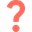
Проанализируйте и изложите содержательный смысл полученных результатов.

## В результате анализа временного ряда пассажиропотока такси Нью-Йорка найдено 15 диссонансов - участков, которые наиболее сильно отличаются от остальных фрагментов ряда. На графике матричного профиля они соответствуют высоким пикам, поскольку расстояния до ближайших похожих подпоследовательностей для них значительно больше обычных. Наиболее заметные отклонения сосредоточены ближе к концу временного ряда, хотя отдельные диссонансы встречаются и в начале, и в середине наблюдений. Это указывает на периоды нетипичного изменения пассажиропотока, когда привычный суточный характер колебаний нарушается. Такие изменения могут быть связаны с праздниками, погодными условиями или другими событиями, влияющими на спрос на такси. Таким образом, матричный профиль позволяет выделить необычные периоды пассажиропотока без предварительного задания порогов аномальности.

## **Часть 2.** Сегментация повторяющихся активностей.

### **Задача 4.**

Загрузите временной ряд PAMAP *pamap.csv* из директории *./datasets/part2/*, представляющий собой показания закрепленного на человеке виброакселерометра. Данный ряд включает показания, снятые при выполнении человеком трех видов физической активности: ходьба, подъем по лестнице и спуск по лестнице. Необходимо сегментировать временной ряд на основе его матричного профиля для определения того, когда человек шел и когда поднимался/спускался. Поскольку подъем и спуск по лестнице – это схожие действия, поэтому будем считать, что это одна активность.  

In [15]:
ts_url = './datasets/part2/pamap.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд PAMAP.

In [16]:
plot_ts(ts, "Input time series")

Найдите и визуализируйте матричный профиль временного ряда.

In [17]:
m = 100
excl_zone = m
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts, m, exclusion_zone=excl_zone)

print("Длина матричного профиля:", len(mp['mp']))
print("Минимальное расстояние:", np.min(mp['mp']))
print("Максимальное расстояние:", np.max(mp['mp']))

Длина матричного профиля: 30901
Минимальное расстояние: 0.928973263487293
Максимальное расстояние: inf


In [18]:
plot_ts(mp['mp'], "Matrix Profile")

Вычислите порог по формуле, которая представлена в презентации [04 Matrix profile.pdf](https://github.com/mzym/TimeSeriesCourse/blob/main/slides/04%20Matrix%20profile.pdf).

In [19]:
threshold = 0

# INSERT YOUR CODE
profile = np.asarray(mp['mp'], dtype=float)
valid_values = profile[np.isfinite(profile)]
alpha = 0.55
threshold = alpha * (valid_values.min() + valid_values.max())
print("Порог сегментации:", threshold)

Порог сегментации: 6.8708136343077815


Выполните визуализацию результатов сегментации повторяющихся активностей.

In [20]:
plot_segmentation(mp, threshold)

Загрузите истинную разметку временного ряда PAMAP *pamap_labels.csv*, где 0 означает ходьбу, 1 – подъем по лестнице, 2 – спуск с лестницы. Вычислите точность по метрике accuracy, сравнив полученные результаты по основе матричного профиля с истинной разметкой.

In [21]:
labels_url = './datasets/part2/pamap_labels.csv'

labels = pd.read_csv(labels_url, header=None).squeeze().to_numpy()

In [22]:
profile = np.asarray(mp['mp'], dtype=float)
valid = np.isfinite(profile)

true_labels = labels[m // 2:m // 2 + len(profile)]
true_activity = (true_labels != 0).astype(int)

pred_activity = (profile < threshold).astype(int)

accuracy = np.mean(pred_activity[valid] == true_activity[valid])

print(f"Accuracy: {accuracy:.4f}")
print(f"Точность сегментации: {accuracy * 100:.2f}%")

Accuracy: 0.9421
Точность сегментации: 94.21%


In [24]:
print("Средний MP для ходьбы:",
      np.mean(profile[valid & (true_activity == 0)]))

print("Средний MP для лестницы:",
      np.mean(profile[valid & (true_activity == 1)]))

print("\nМатрица ошибок:")
print(pd.crosstab(
    pd.Series(true_activity[valid], name="Истинный класс"),
    pd.Series(pred_activity[valid], name="Предсказанный класс")
))

Средний MP для ходьбы: 9.558021167255891
Средний MP для лестницы: 3.601318768916634

Матрица ошибок:
Предсказанный класс     0      1
Истинный класс                  
0                    9775   1016
1                     745  18865


## **Чaсть 3.** Casy Study: Раскрытие краж электричества подменой счетчиков (meter-swapping detection).


### **Задача 5.**

Рассмотрим практическое применение использования матричного профиля для решения задачи, связанной с раскрытием краж электричества путем подмены счетчиков.

Загрузите временные ряды из директории *./datasets/part3/*, которые были выбраны случайным образом из набора данных (House 1, 2, 3, 4 и 11), содержащего данные потребления электроэнергии 20 жилых домов в Великобритании с 1 января по 23 декабря 2014 года.

In [40]:
path = './datasets/part3/'

house_idx = [1, 2, 3, 4, 11]

filenames = [f"House{i}.csv" for i in house_idx]

consumptions = {}
for house in filenames:
    consumptions[house[:-4]] = pd.read_csv(os.path.join(path, house), header=None, index_col=0)
    consumptions[house[:-4]].index = pd.to_datetime(consumptions[house[:-4]].index, format='%Y-%m-%d %H:%M:%S')

Далее смоделируем событие замены счетчика. Для этого каждый временной ряд разделим на две части: "Head" (до 1 октября) и "Tail" (после 1 октября). После чего выберем случайным образом 2 временных ряда (например, House1 и House11) и поменяем местами их "Tail" части.

In [41]:
cutoff = pd.to_datetime('2014-10-01')
heads, tails = heads_tails(consumptions, cutoff, house_idx)

#swap Heads and Tails of 1 and 11
swap1, swap2 = 1, 11
consumptions[f'House{swap1}'] = pd.concat([heads[f'H_{swap1}'], tails[f'T_{swap2}']])
consumptions[f'House{swap2}'] = pd.concat([heads[f'H_{swap2}'], tails[f'T_{swap1}']])
heads, tails = heads_tails(consumptions, cutoff, house_idx)

Визуализируйте исходные временные ряды и параллельную оси OY прямую, которая делит временные ряды на "Head" и "Tail" части.

In [42]:
plot_consumptions_ts(consumptions, cutoff, house_idx)

Чтобы найти переставленную пару временных рядов, выполним следующее. Сначала составим временные ряды $H_i$ из всевозможных комбинаций "Head" и "Tail" частей исходных временных рядов $T_K$, где $1 \leq i \leq |T|^2$, $1 \leq K \leq |T|$. В нашем случае, $|T| = 5$.  Далее среди них найдем такую пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$. Минимальная оценка $swap\_score$ для пары рядов $(H_i, H_j)$ вычисляется следующим образом:

\begin{equation}
swap\_score(i,j) = \frac{\min{(Head_{H_i} \bowtie Tail_{H_j})}}{\min{(Head_{H_i} \bowtie Tail_{H_i})}+eps},
\end{equation}

где $\bowtie$ – операция нахождения матричного профиля между двумя временными рядами. Матричный профиль между двумя временными рядами содержит расстояния между всеми подпоследовательностями первого временного ряда и их ближайшими соседями, которые являются подпоследовательностями второго временного ряда.

Добавьте в функцию `compute_mp()` в модуле *mp.py* поддежку вычисления матричного профиля между двумя различными временными рядами и найдите пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$ среди всех пар.

In [43]:
m = 24 * 4

min_score = meter_swapping_detection(heads, tails, house_idx, m)

In [53]:
min_i, min_j, mp_j = min_score['i'], min_score['j'], min_score['mp_j']
print(f'Time series with minimum score is (H_{min_i}, T_{min_j}).')

Time series with minimum score is (H_11, T_1).


In [54]:
print(f"Minimum swap-score: {min_score['score']:.4f}")

Minimum swap-score: 0.5078



## В результате анализа временных рядов энергопотребления пяти домов с помощью матричного профиля обнаружена подмена показаний электросчетчиков. Минимальное значение swap-score составило 0,5078 для пары H_11 и T_1. Полученный результат соответствует смоделированной подмене между домами № 1 и № 11. Таким образом, использование матричного профиля позволило выявить несоответствие между показаниями электросчетчиков до и после подмены.

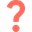
Проанализируйте и изложите содержательный смысл полученных результатов.

*# WRITE YOUR ANSWER*